# Rain in Australia Prediction
Выполнила: Китаева Дарья

Устанавливаем catboost, а также подключаем библиотеки, что будем использовать.

In [ ]:
!pip install CatBoost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 5.5 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, classification_report
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import SelectKBest, mutual_info_classif

Подключаем Google Drive и считываем наш файл для дальнейшего использования.
(Т.к я делала в Google Colab у меня подключается Диск, но для работы в среде программирования, к примеру VS Code, следует убрать все строчки предшуствующие df = pd.read_csv(...) и вместо многоточия вставить название файла).

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')
df = pd.read_csv("/content/drive/MyDrive/weatherAUS.csv", sep=",")
df.head()

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


Выводим наш датафрейм и можем заметить, что у нас 23 столбца. Наша целевая переменная - дождь завтра, она и дождь сегодня являются строками, для дальнейшего исопльзования переведем их в бинарные, т.е 1 и 0.

In [ ]:
df['RainTomorrow_numbers'] = df['RainTomorrow'].map({'No': 0, 'Yes': 1})
df['RainToday_numbers'] = df['RainToday'].map({'No': 0, 'Yes': 1})

Для наглядности посмотрим корелляцию между всеми числовыми признаками, особое внмание уделив нашей целевой перемнной.

<Axes: >

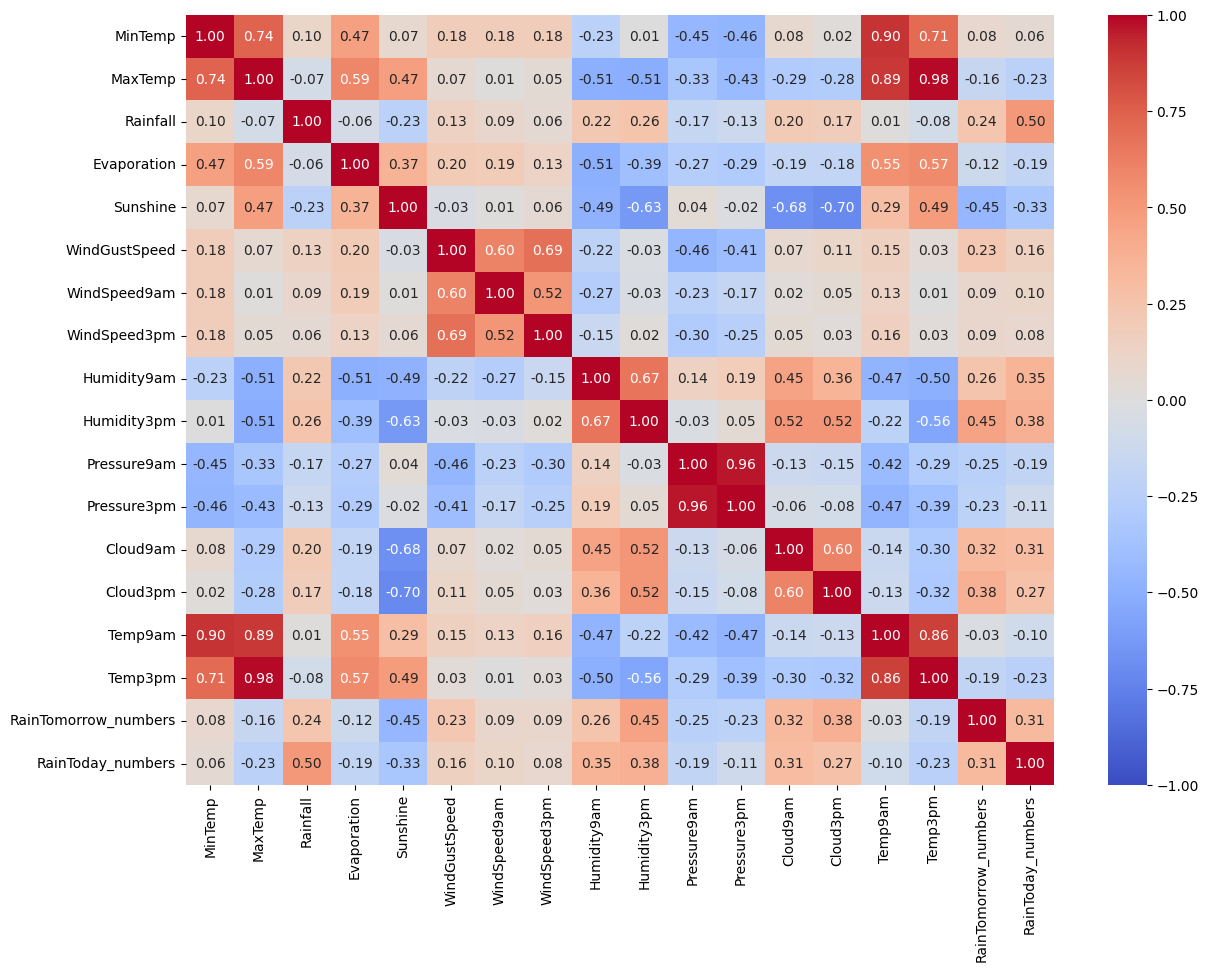

In [ ]:
numeric_columns = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm',
    'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainTomorrow_numbers', 'RainToday_numbers'
]
correlation_matrix = df[numeric_columns].corr()
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')

In [ ]:
spearman_corr = df[numeric_columns].corr(method='spearman')['RainTomorrow_numbers'].drop('RainTomorrow_numbers')
print(spearman_corr.sort_values(ascending=False))

Humidity3pm          0.431174
Cloud3pm             0.394079
Rainfall             0.331791
Cloud9am             0.324619
RainToday_numbers    0.313097
Humidity9am          0.267172
WindGustSpeed        0.212351
WindSpeed9am         0.081418
MinTemp              0.076493
WindSpeed3pm         0.076321
Temp9am             -0.030278
Evaporation         -0.137629
MaxTemp             -0.158756
Temp3pm             -0.193068
Pressure3pm         -0.215426
Pressure9am         -0.235770
Sunshine            -0.438469
Name: RainTomorrow_numbers, dtype: float64


Как мы можем видеть главный признак, предшествующий дождю - влажность сегодня днем, далее облачность вечером, осадки/ливень; отрицательно же влияет солнечная погода, атмосферное давление, что утром, что вечером, а также температура.

In [ ]:
pd.crosstab(
    df['RainToday'], df['RainTomorrow'],
    normalize='index'
).round(2)

RainTomorrow,No,Yes
RainToday,,
No,0.85,0.15
Yes,0.54,0.46


Как мы можем видеть, если сегодня дождь, то в 46% завтра тоже будет дождь, если сегодня не было дождя, то он будет в 15% случаев.

In [ ]:
print((df.isna().sum()/len(df)*100).round(2))

Date                     0.00
Location                 0.00
MinTemp                  0.45
MaxTemp                  0.23
Rainfall                 0.99
Evaporation             42.79
Sunshine                47.69
WindGustDir              6.56
WindGustSpeed            6.52
WindDir9am               7.04
WindDir3pm               2.66
WindSpeed9am             0.95
WindSpeed3pm             1.85
Humidity9am              1.25
Humidity3pm              2.54
Pressure9am              9.86
Pressure3pm              9.83
Cloud9am                37.74
Cloud3pm                40.15
Temp9am                  0.64
Temp3pm                  1.92
RainToday                0.99
RainTomorrow             0.00
RainTomorrow_numbers     0.00
RainToday_numbers        0.99
Month                    0.00
dtype: float64


Смотрим сколько процентов пропущенных значений в столбцах.

In [ ]:
for col in ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm']:
    rate = (
        df.groupby(col)['RainTomorrow']
          .apply(lambda s: (s == 'Yes').mean())
          .sort_values(ascending=False)
          .round(3)
    )
    print(rate)

Location
Portland            0.364
Walpole             0.316
Cairns              0.312
Dartmoor            0.306
NorfolkIsland       0.305
MountGambier        0.303
Albany              0.297
Witchcliffe         0.292
CoffsHarbour        0.289
MountGinini         0.269
NorahHead           0.269
Darwin              0.267
Sydney              0.259
SydneyAirport       0.257
Ballarat            0.257
GoldCoast           0.255
Watsonia            0.245
Newcastle           0.241
Hobart              0.238
Wollongong          0.235
Williamtown         0.233
Launceston          0.230
Brisbane            0.222
MelbourneAirport    0.217
Adelaide            0.215
Sale                0.214
Albury              0.203
Perth               0.202
Melbourne           0.199
Nuriootpa           0.197
Penrith             0.196
BadgerysCreek       0.194
PerthAirport        0.188
Tuggeranong         0.187
Richmond            0.186
Bendigo             0.185
Canberra            0.183
WaggaWagga          0.178
Tow

Анализируем связь между категориальными признаками и целевой переменной, можем сказать в каких городах чаще дождь, а также какой ветер этому предшествует.

In [ ]:
print((df['RainTomorrow'] == 'Yes').sum()/len(df['RainTomorrow'])*100)

21.914615701911178


Проверяем, сколько в процентах, у нас 'Yes', т.е, что дождь будет завтра. Можем заметить, что у нас присутвует дисбаланс классов.

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month

Дата - излишняя информация и лучше её заменить на месяц, т.к будет прослеживаться более явная сезонность.

<Axes: xlabel='Month'>

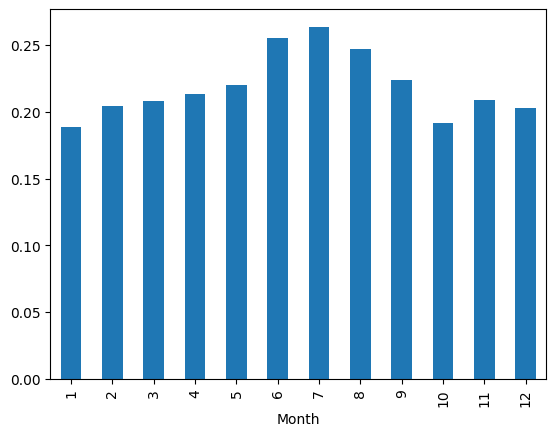

In [ ]:
df.groupby('Month')['RainTomorrow'].apply(lambda x: (x == 'Yes').mean()).plot(kind='bar')

Как мы можем видеть чаще всего дожди случаются в Австралии летом(для них это зима).

In [ ]:
df = df.dropna(subset=['RainTomorrow_numbers']).reset_index(drop=True)

Удаляем все пропуски, которые у нас есть в столбце целевой переменной, т.к с ними модели не смогут работать.

In [ ]:
cols = ['Location','MinTemp','MaxTemp','Rainfall','Sunshine', 'WindGustDir','WindGustSpeed','WindDir9am',
    'Humidity9am','Humidity3pm','Pressure9am','Pressure3pm', 'Cloud9am','Cloud3pm','Temp3pm', 'RainToday_numbers','Month', 'RainTomorrow_numbers'
]

catboost = df[cols].copy()
forest = df[cols].copy()

logreg_cols = [c for c in cols if c != 'Pressure9am']
logreg = df[logreg_cols].copy()

Для моделей испольузем только столбцы, которые несут информацию, следуя из нашего отбора, на основе того, в каких столбцах много пропусков(они почти неинформативны, тк при заполнении данных, они будут уже нереальными), а также смотрим на корреляцию. Для линейной регрессии не берем во внимание столбец с давлением в 9 утра, т.к у нас есть мультиколлинеарность, что будет мешать модели предсказывать. (Для catboost и леса это не критично).

In [ ]:
target = 'RainTomorrow_numbers'
X_cb = catboost.drop(columns=[target])
y_cb = catboost[target].astype(int)

X_cb_tr, X_cb_te, y_cb_tr, y_cb_te = train_test_split(
    X_cb, y_cb, test_size=0.2, random_state=42, stratify=y_cb
)

X_rf = forest.drop(columns=[target])
y_rf = forest[target].astype(int)

X_rf_tr, X_rf_te, y_rf_tr, y_rf_te = train_test_split(
    X_rf, y_rf, test_size=0.2, random_state=42, stratify=y_rf
)

X_lr = logreg.drop(columns=[target])
y_lr = logreg[target].astype(int)

X_lr_tr, X_lr_te, y_lr_tr, y_lr_te = train_test_split(
    X_lr, y_lr, test_size=0.2, random_state=42, stratify=y_lr
)

Разбиваем наши данные на выборки: train и test.

In [60]:
cat_cols = ['Location', 'WindGustDir', 'WindDir9am']
cat_idx = [X_cb_tr.columns.get_loc(c) for c in cat_cols]
for col in cat_cols:
    X_cb_tr[col] = X_cb_tr[col].fillna('Unknown').astype(str)
    X_cb_te[col] = X_cb_te[col].fillna('Unknown').astype(str)

cb = CatBoostClassifier(iterations=500, depth=6, learning_rate=0.05, cat_features=cat_idx, auto_class_weights='Balanced', verbose=100, random_state=42)
cb.fit(X_cb_tr, y_cb_tr)
pred_cb = cb.predict(X_cb_te)
print(f1_score(y_cb_te, pred_cb, average='macro'))

0:	learn: 0.6727568	total: 251ms	remaining: 2m 5s
100:	learn: 0.4424125	total: 18.7s	remaining: 1m 13s
200:	learn: 0.4216731	total: 47.3s	remaining: 1m 10s
300:	learn: 0.4080883	total: 1m 4s	remaining: 42.7s
400:	learn: 0.3977013	total: 1m 20s	remaining: 19.8s
499:	learn: 0.3900615	total: 1m 35s	remaining: 0us
0.7709478941553355


CatBoost показал хороший, но не идеальный результат. Модель хорошо справляется с задачей предсказания дождя на завтра. Метрика может быть не идеальна, т.к присутсвует дисбаланс классов.

In [61]:
num_cols = [c for c in X_rf_tr.columns if c not in cat_cols]

for col in num_cols:
    med = X_rf_tr[col].median()
    X_rf_tr[col] = X_rf_tr[col].fillna(med)
    X_rf_te[col] = X_rf_te[col].fillna(med)

for col in cat_cols:
    mode = X_rf_tr[col].mode()[0]
    X_rf_tr[col] = X_rf_tr[col].fillna(mode)
    X_rf_te[col] = X_rf_te[col].fillna(mode)

enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
enc.fit(X_rf_tr[cat_cols])

tr_enc = pd.DataFrame(enc.transform(X_rf_tr[cat_cols]), columns=enc.get_feature_names_out(cat_cols), index=X_rf_tr.index)
te_enc = pd.DataFrame(enc.transform(X_rf_te[cat_cols]), columns=enc.get_feature_names_out(cat_cols), index=X_rf_te.index)

X_rf_tr_f = pd.concat([X_rf_tr[num_cols], tr_enc], axis=1)
X_rf_te_f = pd.concat([X_rf_te[num_cols], te_enc], axis=1)

rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', n_jobs=-1, random_state=42)
rf.fit(X_rf_tr_f, y_rf_tr)
pred_rf = rf.predict(X_rf_te_f)
print(f1_score(y_rf_te, pred_rf, average='macro'))

0.7613146301224358


CatBoost показало преимущество перед RandomFOrest. Разница составляет менее 0.01, что объясняется способностью градиентного бустинга последовательно исправлять ошибки.

In [64]:
num_cols = [c for c in X_lr_tr.columns if c not in cat_cols]
for col in num_cols:
    med = X_lr_tr[col].median()
    X_lr_tr[col] = X_lr_tr[col].fillna(med)
    X_lr_te[col] = X_lr_te[col].fillna(med)

for col in cat_cols:
    mode = X_lr_tr[col].mode()[0]
    X_lr_tr[col] = X_lr_tr[col].fillna(mode)
    X_lr_te[col] = X_lr_te[col].fillna(mode)

enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
enc.fit(X_lr_tr[cat_cols])

tr_enc = pd.DataFrame(enc.transform(X_lr_tr[cat_cols]), columns=enc.get_feature_names_out(cat_cols), index=X_lr_tr.index)
te_enc = pd.DataFrame(enc.transform(X_lr_te[cat_cols]), columns=enc.get_feature_names_out(cat_cols), index=X_lr_te.index)

X_lr_tr_f = pd.concat([X_lr_tr[num_cols], tr_enc], axis=1)
X_lr_te_f = pd.concat([X_lr_te[num_cols], te_enc], axis=1)

scaler = StandardScaler()
X_lr_tr_s = scaler.fit_transform(X_lr_tr_f)
X_lr_te_s = scaler.transform(X_lr_te_f)

lr = LogisticRegression(penalty='l2', C=1.0, max_iter=1000, class_weight='balanced', random_state=42)
lr.fit(X_lr_tr_s, y_lr_tr)
pred_lr = lr.predict(X_lr_te_s)
print(f1_score(y_lr_te, pred_lr, average='macro'))

0.7393136670360833


На основе результата у Логистической регрессии можем сделать вывод, что в наших данных присутсвуют таки линейно связанные с нашей переменной признаки, но присутвуют и нелинейные, т.к она оказалась хуже, чем две предыдущие. Как и ожидалось, она показала наихудший результат из 3х моделей.

In [65]:
print(f"LogReg:   {accuracy_score(y_lr_te, pred_lr):.4f}")
print(f"RF:       {accuracy_score(y_rf_te, pred_rf):.4f}")
print(f"CatBoost: {accuracy_score(y_cb_te, pred_cb):.4f}")

LogReg:   0.7903
RF:       0.8573
CatBoost: 0.8187


Выше представлены результаты по метрике Accuracy у трех моделей и здесь Лес Решений обошёл и CatBoost, и Логистическую регрессию.

In [69]:
selector = SelectKBest(mutual_info_classif, k=10)
X_sel_tr = selector.fit_transform(X_rf_tr_f, y_rf_tr)
X_sel_te = selector.transform(X_rf_te_f)

print("Отобрано:", X_rf_tr_f.columns[selector.get_support()].tolist())

Отобрано: ['Rainfall', 'Sunshine', 'WindGustSpeed', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'RainToday_numbers']


Как мы можем заметить у нас были отобраны признаки с наибольшей и наименьшей корреляцией, совпадающие с ручным отбором признаков.

# Вывод
В ходе работы решалась задача прогнозирования дождя на завтра в Австралии на основе метеорологических данных. После разведочного анализа и проверки мультиколлинеарности были обучены три модели: логистическая регрессия, лес решений и CatBoost. Сравнение по accuracy и F1 выявило: по accuracy лучшей оказалась RandomForest, по F1 же это CatBoost, что объясняется дисбалансом классов. Логистическая регрессия показала наихудший результат, подтвердив наличие нелинейных зависимостей.